<a href="https://colab.research.google.com/github/aravinth963/DATA-SCIENCE/blob/main/student_mark_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Install dependencies as needed:
# pip install kagglehub[pandas-datasets]
import kagglehub
from kagglehub import KaggleDatasetAdapter

# Set the path to the file you'd like to load
file_path = "student_info(2).csv"

# Load the latest version
df = kagglehub.load_dataset(
  KaggleDatasetAdapter.PANDAS,
  "hkhamnakhalid/machine-learning-student-mark-prediction",
  file_path,
  # Provide any additional arguments like
  # sql_query or pandas_kwargs. See the
  # documenation for more information:
  # https://github.com/Kaggle/kagglehub/blob/main/README.md#kaggledatasetadapterpandas
)

print("First 5 records:", df.head())

/tmp/ipykernel_2412/591480559.py:10: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(


100%|██████████| 2.31k/2.31k [00:00<00:00, 1.20MB/s]

First 5 records:    study_hours  student_marks
0         6.83          78.50
1         6.56          76.74
2          NaN          78.68
3         5.67          71.82
4         8.67          84.19


In [ ]:
print(df.isnull().sum())

study_hours      5
student_marks    0
dtype: int64


In [ ]:
print(df[df["study_hours"].isnull()])

     study_hours  student_marks
2            NaN          78.68
31           NaN          76.14
96           NaN          75.39
122          NaN          76.83
188          NaN          77.27


In [ ]:

median_hours = df["study_hours"].median()

df["study_hours"] = df["study_hours"].fillna(median_hours)

print(df[df["study_hours"].isnull()])

print(df.isnull().sum())

Empty DataFrame
Columns: [study_hours, student_marks]
Index: []
study_hours      0
student_marks    0
dtype: int64


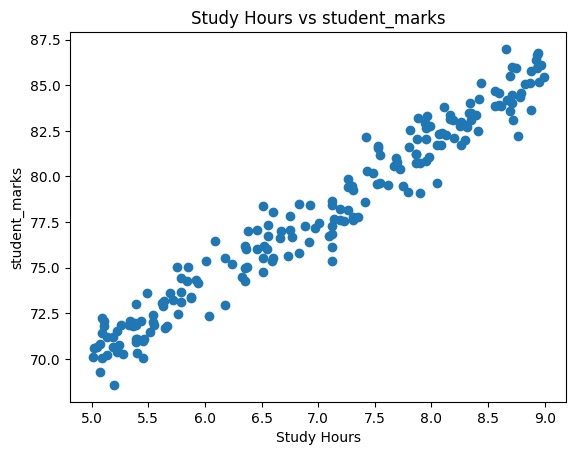

In [ ]:
import matplotlib.pyplot as plt

plt.scatter(df["study_hours"],df["student_marks"])

plt.xlabel("Study Hours")
plt.ylabel("student_marks")
plt.title("Study Hours vs student_marks")

plt.show()

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

X = df[["study_hours"]]
y = df["student_marks"]

model = LinearRegression()

x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model.fit(x_train, y_train)

y_pred = model.predict(x_test)

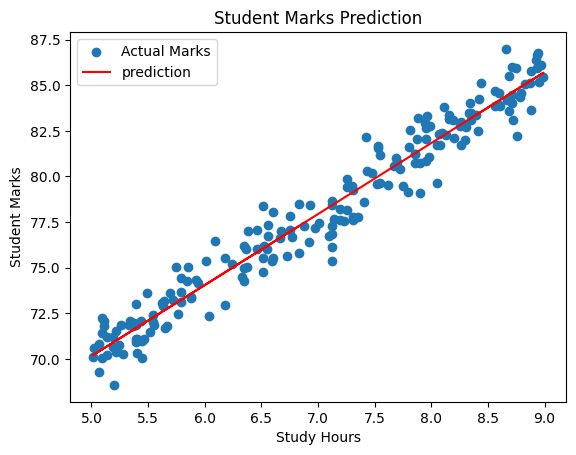

In [ ]:
plt.scatter(X["study_hours"], y, label="Actual Marks")
plt.plot(X['study_hours'],y_pred,color="red",label="prediction")


plt.xlabel("Study Hours")
plt.ylabel("Student Marks")
plt.title("Student Marks Prediction")
plt.legend()
plt.show()

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
MAE = mean_absolute_error(y_test,y_pred)
MSE = mean_squared_error(y_test,y_pred)
RooMSE = np.sqrt(MSE)

variance_actual = np.var(y_test)
RelMSE = MSE / variance_actual if variance_actual != 0 else np.nan

mean_actual = np.mean(y_test)
CV = (RooMSE / abs(mean_actual)) * 100 if mean_actual != 0 else np.nan


CV = RooMSE/np.mean(y_test)*100

print("MAE:", MAE)
print("MSE:", MSE)
print("RMSE:", RooMSE)
print("RelMSE:", RelMSE)
print("CV (%):", CV)

MAE: 0.987019143212984
MSE: 1.4566714653285486
RMSE: 1.2069264539848932
RelMSE: 0.05752087555494862
CV (%): 1.5568925446294166


In [ ]:
import pandas as pd

n = int(input("Enter study hours: "))

new_data = pd.DataFrame({
    "study_hours": [n]
})

prediction = model.predict(new_data)

print("Predicted student marks:", prediction[0])

Enter study hours: 5
Predicted student marks: 70.06253031869895
